# Proyek UTS Data Science
## Klasifikasi Emosi Ulasan Produk Tokopedia Menggunakan TF-IDF, Random Forest, dan XGBoost

1. Business Understanding
- Latar belakang: Ulasan produk Tokopedia mengandung informasi mengenai pengalaman dan emosi pelanggan.
- Permasalahan: Banyaknya ulasan membuat analisis emosi secara manual kurang efisien.
- Tujuan: Membangun model klasifikasi otomatis untuk mengelompokkan ulasan ke dalam lima kelas emosi, yaitu Happy, Love, Sadness, Fear, dan Anger.
- Manfaat: Membantu memahami respons emosional pelanggan terhadap produk berdasarkan ulasan.

## 1. Import library

Library yang digunakan pada tahap Data Understanding.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Memuat dataset

Pastikan file `PRDECT-ID Dataset.csv` berada di folder yang sama dengan notebook. Jika lokasinya berbeda, ubah `DATA_PATH`.

In [2]:
df = pd.read_csv('PRDECT-ID Dataset.csv')

## 3. Memahami struktur data

Memeriksa nama kolom, tipe data, jumlah baris, nilai tidak kosong, dan statistik deskriptif awal.

In [3]:
print("Daftar kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
df.describe()

Daftar kolom:
['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Category         5400 non-null   object 
 1   Product Name     5400 non-null   object 
 2   Location         5400 non-null   object 
 3   Price            5400 non-null   int64  
 4   Overall Rating   5400 non-null   float64
 5   Number Sold      5400 non-null   int64  
 6   Total Review     5400 non-null   int64  
 7   Customer Rating  5400 non-null   int64  
 8   Customer Review  5400 non-null   object 
 9   Sentiment        5400 non-null   object 
 10  Emotion          5400 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 464.2+ KB

Statistik deskriptif:


,Price,Overall Rating,Number Sold,Total Review,Customer Rating
count,5.400000e+03,5400.000000,5400.000000,5400.000000,5400.000000
mean,2.386961e+05,4.854389,15961.951852,2168.645556,3.087037
std,8.016337e+05,0.108259,74201.913338,2915.666035,1.766258
min,1.000000e+02,4.100000,9.000000,4.000000,1.000000
25%,2.000000e+04,4.800000,1630.000000,576.000000,1.000000
50%,5.990000e+04,4.900000,3794.500000,1192.000000,3.000000
75%,1.500000e+05,4.900000,9707.000000,2582.000000,5.000000
max,1.539900e+07,5.000000,1000000.000000,24500.000000,5.000000


## 4. Pemeriksaan kualitas data

Memeriksa nilai kosong, duplikasi seluruh baris, dan duplikasi teks ulasan. Pada tahap Data Understanding, pemeriksaan dilakukan tanpa menghapus atau mengubah data.

In [4]:
missing_summary = pd.DataFrame({
    "Jumlah kosong": df.isna().sum(),
}).sort_values("Jumlah kosong", ascending=False)

display(missing_summary)
print("Duplikasi seluruh baris:", df.duplicated().sum())

if "Customer Review" in df.columns:
    print("Duplikasi teks ulasan:", df["Customer Review"].duplicated().sum())
    print("Jumlah ulasan kosong:", df["Customer Review"].isna().sum())

,Jumlah kosong
Category,0
Product Name,0
Location,0
Price,0
Overall Rating,0
Number Sold,0
Total Review,0
Customer Rating,0
Customer Review,0
Sentiment,0


Duplikasi seluruh baris: 7
Duplikasi teks ulasan: 95
Jumlah ulasan kosong: 0


## 5. Analisis Data Eksploratif (EDA)

EDA awal mencakup distribusi label emosi, panjang teks, kata yang sering muncul per kelas, serta fitur numerik yang dihitung dari teks ulasan. Label sentimen turunan hanya ditampilkan sebagai ringkasan tambahan.

### 5.1 Distribusi kelas emosi

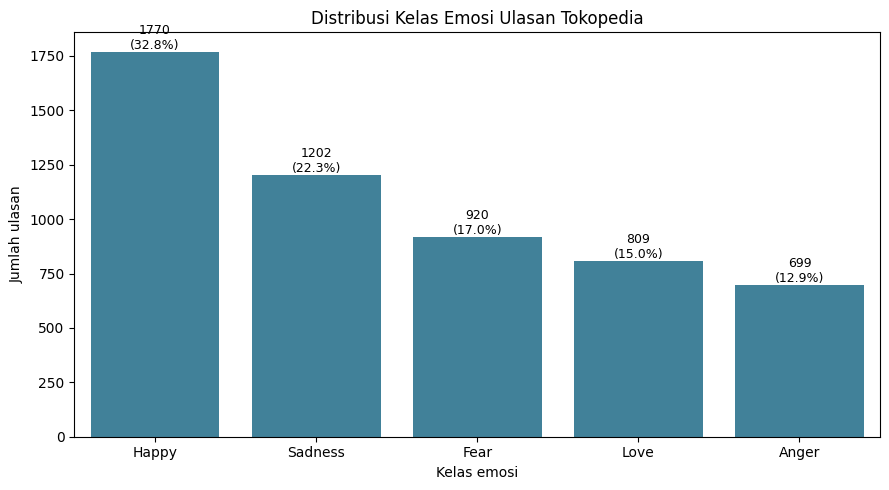

In [5]:
TARGET_COL = "Emotion"
TEXT_COL = "Customer Review"

emotion_counts = (
    df[TARGET_COL].dropna().astype(str).str.strip().str.title()
    .value_counts()
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=emotion_counts.index, y=emotion_counts.values, color="#3288A8")
total = emotion_counts.sum()
for bar, count in zip(ax.patches, emotion_counts.values):
    pct = 100 * count / total if total else 0
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)
plt.title("Distribusi Kelas Emosi Ulasan Tokopedia")
plt.xlabel("Kelas emosi")
plt.ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

### 5.2 Distribusi panjang ulasan

Statistik panjang ulasan:


,Jumlah Kata
count,5400.000000
mean,16.095000
std,15.647181
min,1.000000
25%,7.000000
50%,12.000000
75%,20.000000
max,184.000000


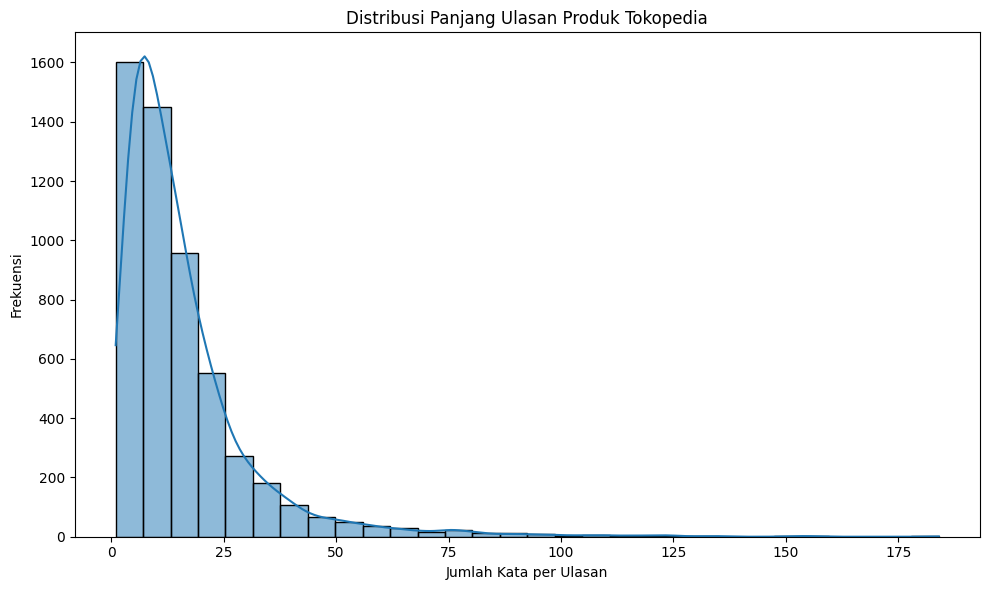

In [6]:
# Mengambil teks yang tidak kosong
reviews = df["Customer Review"].dropna().astype(str)

# Menghitung jumlah kata
review_word_count = reviews.str.split().str.len()

# Statistik deskriptif
print("Statistik panjang ulasan:")
display(review_word_count.describe().to_frame("Jumlah Kata"))

# Histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    review_word_count,
    bins=30,
    kde=True
)

plt.title("Distribusi Panjang Ulasan Produk Tokopedia")
plt.xlabel("Jumlah Kata per Ulasan")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

### 5.3 Distribusi sentimen turunan (tambahan)

Sentimen pada grafik ini dipetakan dari label Emotion, bukan memakai kolom Sentiment sebagai target independen.

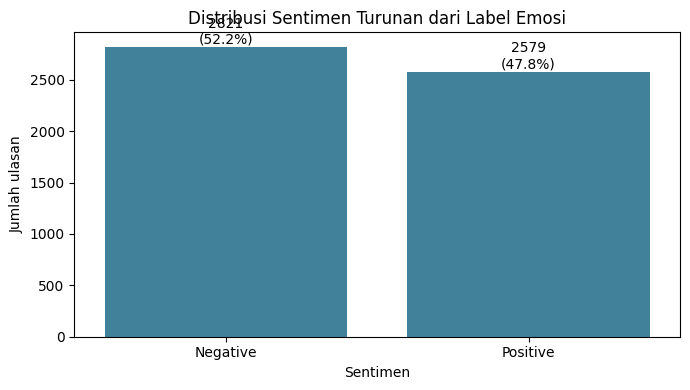

Catatan: sentimen di atas diturunkan dari Emotion. Jangan dipakai sebagai label independen.


In [7]:
# Pemetaan ini hanya ringkasan tambahan, bukan target model utama.
emotion_to_sentiment = {
    "Happy": "Positive",
    "Love": "Positive",
    "Sadness": "Negative",
    "Fear": "Negative",
    "Anger": "Negative"
}

emotion_clean_for_eda = (
    df[TARGET_COL].dropna().astype(str).str.strip().str.title()
)
sentiment_derived = emotion_clean_for_eda.map(emotion_to_sentiment).dropna()
sentiment_counts = sentiment_derived.value_counts().reindex(
    ["Negative", "Positive"], fill_value=0
)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, color="#3288A8")
total_sent = sentiment_counts.sum()
for bar, count in zip(ax.patches, sentiment_counts.values):
    pct = 100 * count / total_sent if total_sent else 0
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count}\n({pct:.1f}%)", ha="center", va="bottom")
plt.title("Distribusi Sentimen Turunan dari Label Emosi")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah ulasan")
plt.tight_layout()
plt.show()

print("Catatan: sentimen di atas diturunkan dari Emotion. Jangan dipakai sebagai label independen.")

### 5.4 Kata yang sering muncul pada tiap kelas emosi

Frekuensi dihitung dari teks yang diubah menjadi huruf kecil. Grafik ini bersifat deskriptif dan bukan hasil pemodelan.

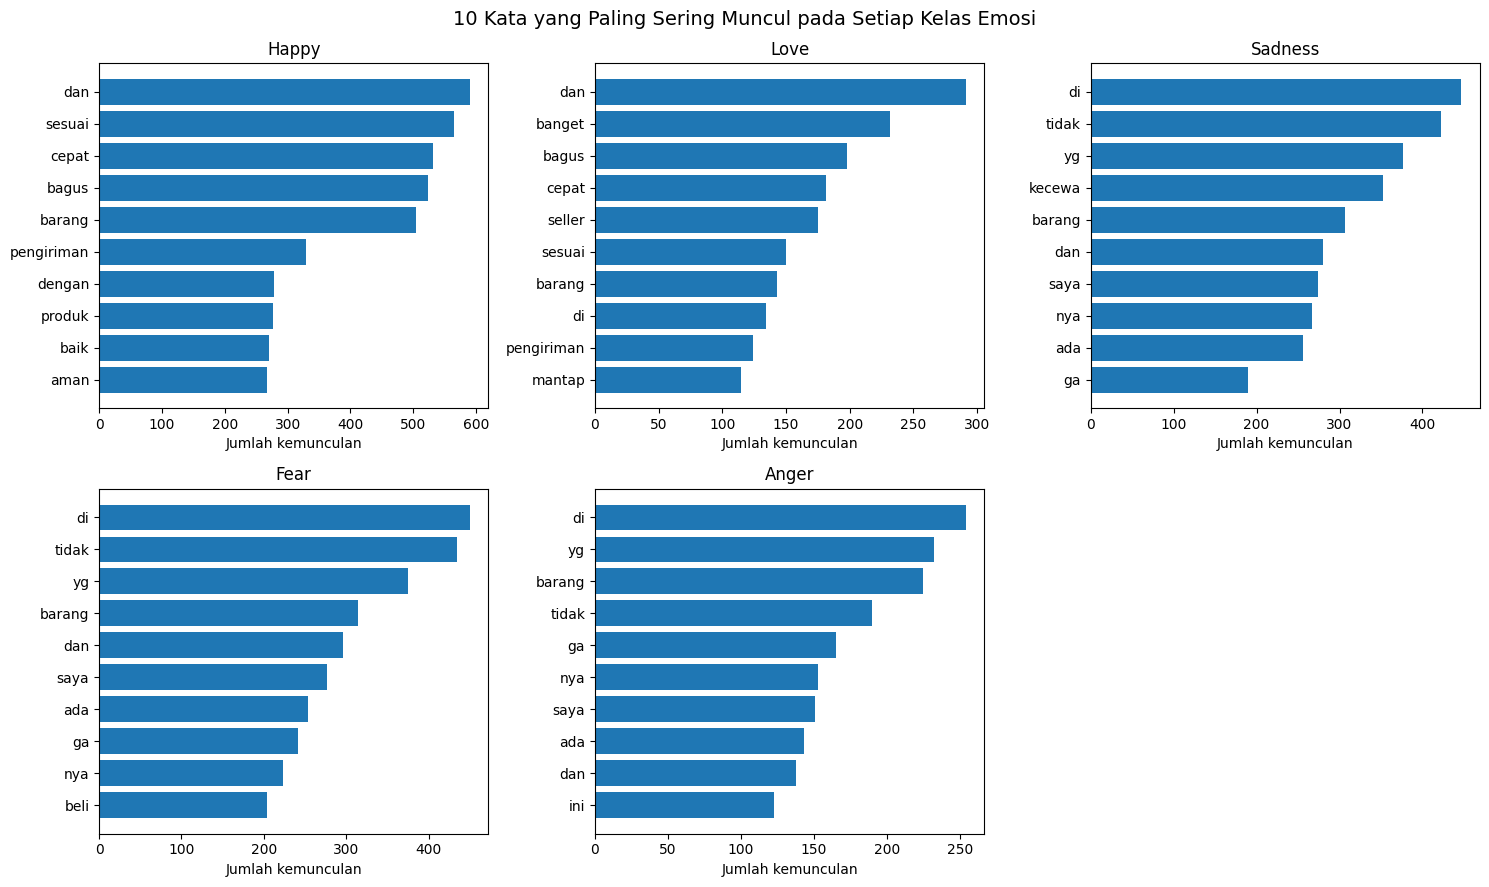

In [8]:
import re
from collections import Counter

# Salin data untuk EDA
df_eda = df[["Customer Review", "Emotion"]].copy()

# Hapus data yang teks atau label emosinya kosong
df_eda = df_eda.dropna(
    subset=["Customer Review", "Emotion"]
)

# Normalisasi teks
df_eda["review_clean"] = (
    df_eda["Customer Review"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Daftar kelas emosi
class_names = ["Happy", "Love", "Sadness", "Fear", "Anger"]

# Membuat subplot 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, emotion in enumerate(class_names):
    # Mengambil ulasan berdasarkan kelas emosi
    reviews = df_eda.loc[
        df_eda["Emotion"].astype(str).str.strip().str.title() == emotion,
        "review_clean"
    ]

    # Menggabungkan semua kata pada kelas tersebut
    all_words = []

    for review in reviews:
        words = re.findall(r"\b[a-zA-Z]+\b", review)
        all_words.extend(words)

    # Menghitung frekuensi kata
    word_counts = Counter(all_words)

    # Mengambil 10 kata yang paling sering muncul
    top_words = word_counts.most_common(10)

    if not top_words:
        axes[i].set_title(f"{emotion} (tidak ada data)")
        axes[i].axis("off")
        continue

    words = [item[0] for item in top_words]
    counts = [item[1] for item in top_words]

    # Membuat grafik batang horizontal
    axes[i].barh(words[::-1], counts[::-1])
    axes[i].set_title(emotion)
    axes[i].set_xlabel("Jumlah kemunculan")
    axes[i].set_ylabel("")

plt.delaxes(axes[5])

plt.suptitle(
    "10 Kata yang Paling Sering Muncul pada Setiap Kelas Emosi",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 5.5 Pemeriksaan outlier dengan IQR

In [9]:
# Menghitung panjang ulasan
eda_df = df.copy()
 
eda_df["review_clean"] = (
    eda_df["Customer Review"]
    .fillna("")
    .astype(str)
    .str.strip()
)

eda_df["jumlah_kata"] = (
    eda_df["review_clean"]
    .str.split()
    .str.len()
)

eda_df["jumlah_karakter"] = (
    eda_df["review_clean"]
    .str.len()
)

# Statistik deskriptif
display(
    eda_df[["jumlah_kata", "jumlah_karakter"]]
    .describe()
    .T
)

# Deteksi outlier dengan metode IQR
for kolom in ["jumlah_kata", "jumlah_karakter"]:
    Q1 = eda_df[kolom].quantile(0.25)
    Q3 = eda_df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = (
        (eda_df[kolom] < batas_bawah) |
        (eda_df[kolom] > batas_atas)
    )

    print(f"\nKolom: {kolom}")
    print(f"Batas bawah: {batas_bawah:.2f}")
    print(f"Batas atas: {batas_atas:.2f}")
    print(f"Jumlah outlier: {outlier.sum()}")
    print(f"Persentase outlier: {outlier.mean() * 100:.2f}%")

,count,mean,std,min,25%,50%,75%,max
jumlah_kata,5400.0,16.095000,15.647181,1.0,7.0,12.0,20.0,184.0
jumlah_karakter,5400.0,103.806667,98.256865,3.0,44.0,78.0,128.0,1058.0



Kolom: jumlah_kata
Batas bawah: -12.50
Batas atas: 39.50
Jumlah outlier: 341
Persentase outlier: 6.31%

Kolom: jumlah_karakter
Batas bawah: -82.00
Batas atas: 254.00
Jumlah outlier: 329
Persentase outlier: 6.09%


### 5.6 Boxplot panjang ulasan

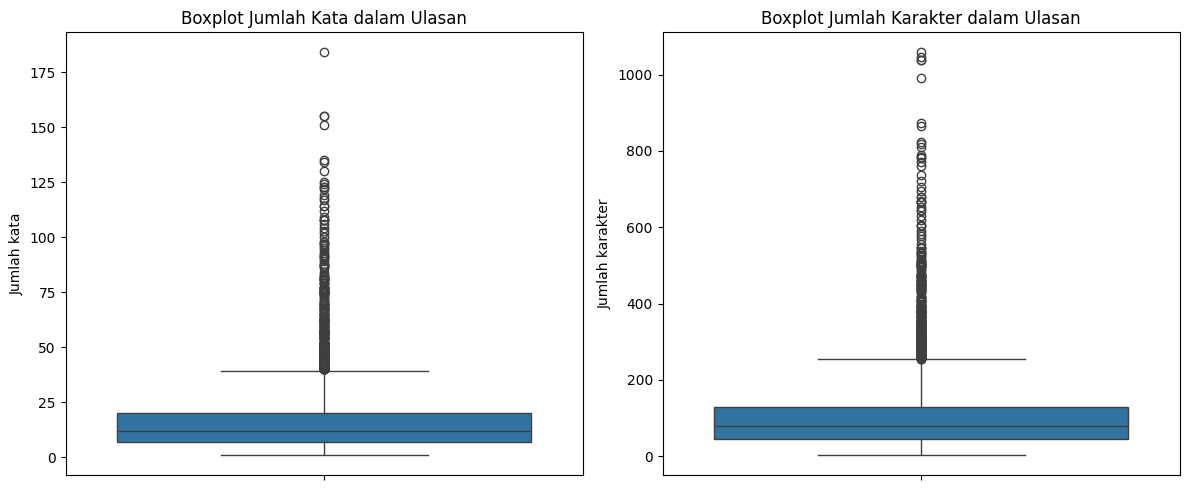

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    y=eda_df["jumlah_kata"],
    ax=axes[0]
)
axes[0].set_title("Boxplot Jumlah Kata dalam Ulasan")
axes[0].set_ylabel("Jumlah kata")

sns.boxplot(
    y=eda_df["jumlah_karakter"],
    ax=axes[1]
)
axes[1].set_title("Boxplot Jumlah Karakter dalam Ulasan")
axes[1].set_ylabel("Jumlah karakter")

plt.tight_layout()
plt.show()

### 5.7 Statistik dan korelasi fitur numerik teks

In [11]:
# Membentuk fitur numerik dari teks ulasan
eda_df["rata_rata_panjang_kata"] = (
    eda_df["review_clean"]
    .apply(
        lambda teks: np.mean(
            [len(kata) for kata in teks.split()]
        ) if teks.split() else 0
    )
)

eda_df["jumlah_tanda_seru"] = (
    eda_df["review_clean"].str.count("!")
)

eda_df["jumlah_tanda_tanya"] = (
    eda_df["review_clean"].str.count(r"\?")
)

eda_df["jumlah_digit"] = (
    eda_df["review_clean"].str.count(r"\d")
)

fitur_numerik = [
    "jumlah_kata",
    "jumlah_karakter",
    "rata_rata_panjang_kata",
    "jumlah_tanda_seru",
    "jumlah_tanda_tanya",
    "jumlah_digit"
]

display(eda_df[fitur_numerik].describe().T)

,count,mean,std,min,25%,50%,75%,max
jumlah_kata,5400.0,16.095000,15.647181,1.000000,7.000000,12.000,20.00,184.0
jumlah_karakter,5400.0,103.806667,98.256865,3.000000,44.000000,78.000,128.00,1058.0
rata_rata_panjang_kata,5400.0,5.851025,1.827068,2.857143,5.049405,5.625,6.25,49.0
jumlah_tanda_seru,5400.0,0.168889,1.569645,0.000000,0.000000,0.000,0.00,99.0
jumlah_tanda_tanya,5400.0,0.695741,2.933829,0.000000,0.000000,0.000,0.00,90.0
jumlah_digit,5400.0,0.485000,1.400446,0.000000,0.000000,0.000,0.00,21.0


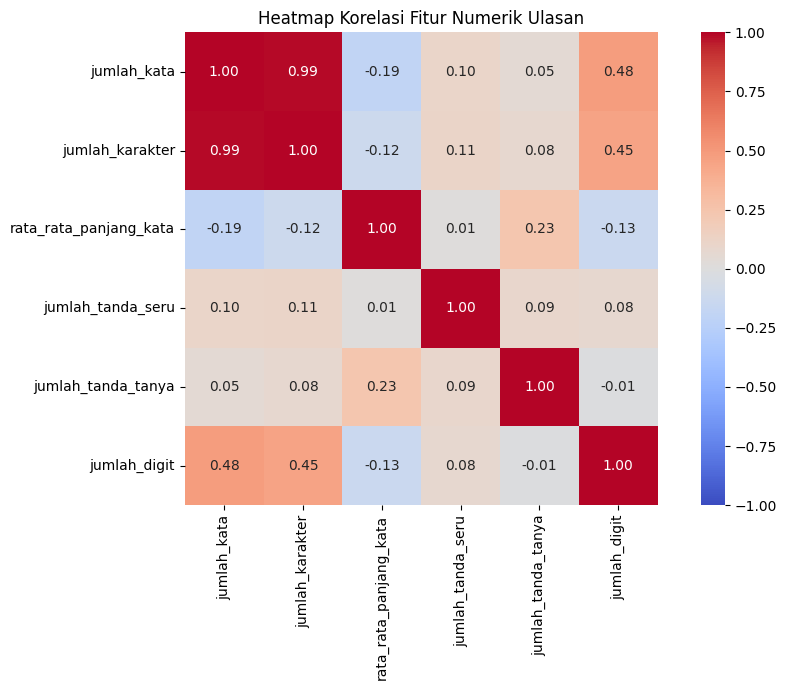

In [12]:
korelasi = eda_df[fitur_numerik].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Heatmap Korelasi Fitur Numerik Ulasan")
plt.tight_layout()
plt.show()

## Data cleaning

In [13]:
df_clean = df.drop_duplicates().copy()

df_clean = df_clean.reset_index(drop=True)

print("Jumlah data sebelum cleaning:", len(df))
print("Jumlah data setelah menghapus duplikat:", len(df_clean))
print("Jumlah data yang dihapus:", len(df) - len(df_clean))

Jumlah data sebelum cleaning: 5400
Jumlah data setelah menghapus duplikat: 5393
Jumlah data yang dihapus: 7


In [14]:
import re

# Menghapus duplikasi seluruh baris
df_clean = df_clean.drop_duplicates().copy()

# Menghapus data yang tidak memiliki ulasan atau label emosi
df_clean = df_clean.dropna(
    subset=["Customer Review", "Emotion"]
).copy()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = text.replace("\ufffd", " ")
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Membersihkan teks ulasan
df_clean["clean_review"] = (
    df_clean["Customer Review"].apply(clean_text)
)

# Membersihkan label emosi
df_clean["Emotion"] = (
    df_clean["Emotion"]
    .astype(str)
    .str.strip()
    .str.title()
)

print("Jumlah data setelah cleaning:", len(df_clean))

display(
    df_clean[
        ["Customer Review", "clean_review", "Emotion"]
    ].head(10)
)

Jumlah data setelah cleaning: 5393


,Customer Review,clean_review,Emotion
0,Alhamdulillah berfungsi dengan baik. Packaging...,alhamdulillah berfungsi dengan baik packaging ...,Happy
1,"barang bagus dan respon cepat, harga bersaing ...",barang bagus dan respon cepat harga bersaing d...,Happy
2,"barang bagus, berfungsi dengan baik, seler ram...",barang bagus berfungsi dengan baik seler ramah...,Happy
3,bagus sesuai harapan penjual nya juga ramah. t...,bagus sesuai harapan penjual nya juga ramah tr...,Happy
4,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",barang bagus pengemasan aman dapat berfungsi d...,Happy
5,"barang bagus, seller ramah..",barang bagus seller ramah,Happy
6,mantap paten joss,mantap paten joss,Happy
7,"Works fine. Respon seller cepat, barang berfun...",works fine respon seller cepat barang berfungs...,Happy
8,barang bagus.. segel.. utuh.. original.. berfu...,barang bagus segel utuh original berfungsi den...,Happy
9,Barang datang dan berfungsi dengan baik dan te...,barang datang dan berfungsi dengan baik dan te...,Happy


## Data preprocessing

In [15]:
# Memeriksa teks kosong setelah cleaning
empty_reviews = (
    df_clean["clean_review"].str.len() == 0
).sum()

print("Jumlah teks kosong:", empty_reviews)

# Menghapus data dengan teks kosong
df_clean = df_clean[
    df_clean["clean_review"].str.len() > 0
].copy()

# Reset index
df_clean = df_clean.reset_index(drop=True)

# Memeriksa distribusi kelas emosi
print("Jumlah data setelah preprocessing:", len(df_clean))

display(
    df_clean["Emotion"].value_counts().to_frame("Jumlah Data")
)

Jumlah teks kosong: 0
Jumlah data setelah preprocessing: 5393


,Jumlah Data
Emotion,
Happy,1768
Sadness,1201
Fear,918
Love,808
Anger,698


## Menentukan fitur dan target

In [16]:
# Menentukan fitur
X = df_clean["clean_review"]

# Menentukan target
y = df_clean["Emotion"]

print("Jumlah data fitur:", len(X))
print("Jumlah data target:", len(y))

Jumlah data fitur: 5393
Jumlah data target: 5393


##  Membagi data latih dan data uji

In [17]:
from sklearn.model_selection import GroupShuffleSplit

# Menggunakan nama produk sebagai kelompok pembagian data
groups = df_clean["Product Name"]

# Membagi data menjadi training dan testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Data training
X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

# Data testing
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 4399
Jumlah data uji: 994


## Encoding

In [18]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Mengubah label training menjadi angka
y_train_encoded = label_encoder.fit_transform(y_train)

# Mengubah label testing menggunakan encoder yang sama
y_test_encoded = label_encoder.transform(y_test)

# Menampilkan pemetaan label
print("Pemetaan Label Emosi:")
for index, label in enumerate(label_encoder.classes_):
    print(f"{label} = {index}")

Pemetaan Label Emosi:
Anger = 0
Fear = 1
Happy = 2
Love = 3
Sadness = 4
